# Real hardware

[← Part 2: noise](02_noise.ipynb) · **Part 3 of 3** · you are here: the
detector on real IBM quantum computers · [README](../README.md)

**Question.** Does the detector find wins on a real quantum computer, and how
far is the hardware from the simulations of Part 2?

Every job in `results/` that ran on a real device is read back here: the
headline first, then what was sent, the noise measured in each job, every
board, and a conclusion. Each job holds 20 calibration circuits next to its
boards (Part 2, section 3; jobs saved before the double wins were added hold
18). Everything is read from the saved records, so re-running this notebook is
free and needs no account. Sending a new job is in the appendix at the end.

In [1]:
import matplotlib.pyplot as plt

from qttt import plots
from qttt.analysis import describe, jobs, rescore, summarize, verdict, wrong_winners
from qttt.board import SHORT_LINE_NAMES
from qttt.results import RunStore
from qttt.stats import wilson_interval

STORE = RunStore("../results")
HARDWARE_ONLY = True  # False also shows simulated jobs saved in STORE (the tests use this)

## Headline

The share of wins found comes with a 95% *Wilson interval*: the range the true
rate plausibly lies in, given how many boards were run. With few boards it is
wide, which is the honest size of what a small batch can show.

**51 boards on ibm_marrakesh, in 2 jobs.** Wins found on **22 of 34** boards with a winner (95% interval 48%–79%); boards without a winner: 17, with 0 false flags. **No reported winner was ever wrong**: every flagged line is checked on the board.

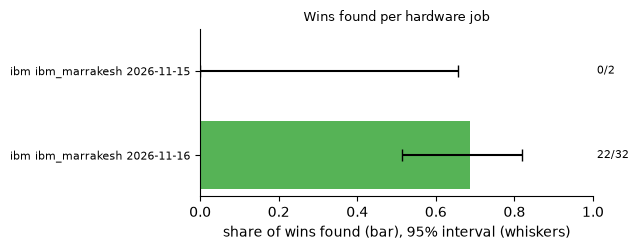

In [2]:
saved = [rescore(job) for job in jobs(STORE, hardware_only=HARDWARE_ONLY)]
if not saved:
    print(f"No hardware results saved yet in {STORE.root}; simulated runs are in 02_noise.")
else:
    detections = [d for job in saved for d in job.detections]
    with_winner = [d for d in detections if d["true_lines"]]
    no_winner = [d for d in detections if not d["true_lines"]]
    found = sum(bool(d["lines"]) for d in with_winner)
    low, high = wilson_interval(found, len(with_winner))
    assert not wrong_winners(detections)
    devices = ", ".join(sorted({job.backend["name"] for job in saved}))
    display(plots.markdown(
        f"**{len(detections)} boards on {devices}, in {len(saved)} job{'s' if len(saved) > 1 else ''}.** "
        f"Wins found on **{found} of {len(with_winner)}** boards with a winner (95% interval {low:.0%}–{high:.0%}); "
        f"boards without a winner: {len(no_winner)}, with {sum(len(d['rejected']) for d in no_winner)} false flags. "
        "**No reported winner was ever wrong**: every flagged line is checked on the board."))
    rows = [(job.label, sum(bool(d["lines"]) for d in job.detections if d["true_lines"]),
             sum(bool(d["true_lines"]) for d in job.detections)) for job in saved]
    plots.found_by_job(rows, "Wins found per hardware job")
    plt.show()

## Example boards, as the circuit saw them

A few of the boards sent, with the hardware's output drawn on each: every
winning line is drawn through its cells, as thick as its share of the shots,
with its index and share written where it leaves the board (bold once it
reached its cutoff). On a perfect device a single winning line carries about
78% of the shots ([Part 1, section 8](01_how_it_works.ipynb)), and each losing
line about 12.5% by chance. Shown: one board of each kind per job, then the
boards the detector got wrong, up to 8.

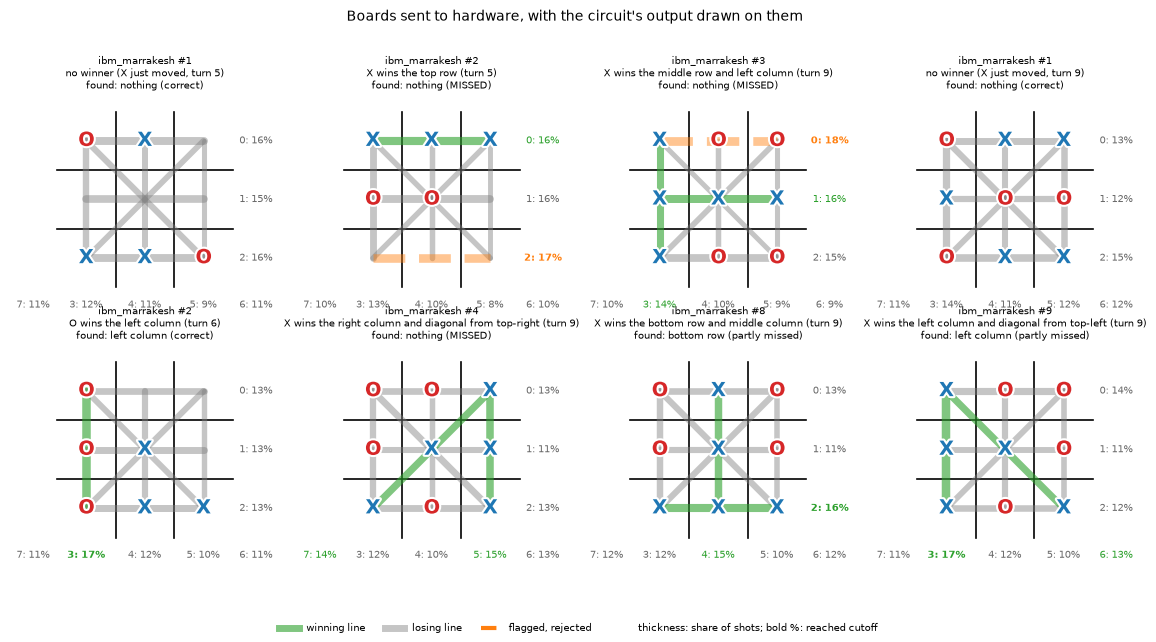

In [3]:
EXAMPLES = 8

examples = []
for job in saved:
    numbered = list(enumerate(job.detections, start=1))
    firsts = [next((n, r) for n, r in numbered if r["label"] == label)
              for label in dict.fromkeys(r["label"] for _, r in numbered)]
    wrong = [(n, r) for n, r in numbered if verdict(r) != "correct" and (n, r) not in firsts]
    examples += [(job, n, r) for n, r in firsts + wrong]
if examples:
    plots.board_results(
        [(r["board"], r["counts"], r["cutoffs"], r["true_lines"], r["rejected"],
          f"{job.backend['name']} #{n}\n{describe(r)}\nfound: "
          f"{' and '.join(SHORT_LINE_NAMES[i] for i in r['lines']) or 'nothing'} ({verdict(r)})")
         for job, n, r in examples[:EXAMPLES]], "Boards sent to hardware, with the circuit's output drawn on them")
    plt.show()

## 1. Saved jobs

One line per job, oldest first: the device's own calibration date, the
compiled circuit and the error-suppression options it ran with.

<details><summary>How the verdicts are computed</summary>

Every verdict below is recomputed from the job's saved counts with the current
calibration rule (`qttt.analysis.rescore`): the profile is fitted again from
the calibration counts saved with the job, so a job collected under an older
rule is scored the same way as a new one. The verdicts decided at run time
stay in the saved records.
</details>

In [4]:
listing = []
for job in saved:
    b, m = job.backend, job.first["metrics"]
    changed = sum(d["lines"] != d["lines_at_run"] for d in job.detections)
    listing.append(
        f"- **{job.label}**: tag `{job.first['tag']}`, job `{job.first['job_id']}`, {len(job.detections)} boards, "
        f"{job.first['shots']} shots, device calibration data from {b['calibration_date'] or 'unpublished'}. "
        f"Circuit: {m['two_qubit_gates']} two-qubit gates, depth {m['depth']}, line qubits {m['line_qubits']}, "
        f"ancilla {'yes' if m.get('ancilla') else 'no'}; Sampler options: {b['options'].get('sampler_options') or 'none'}."
        + (f" Re-scored with the current calibration rule: {changed} board(s) differ from the verdict at run time."
           if changed else ""))
if saved:
    display(plots.markdown("\n".join(listing)))

- **ibm ibm_marrakesh 2026-11-15**: tag `marrakesh-batch-1`, job `dbsumtnasvbs73b945k0`, 3 boards, 1024 shots, device calibration data from 2026-11-13T12:22:56-05:00. Circuit: 431 two-qubit gates, depth 1079, line qubits [53, 54, 39], ancilla yes; Sampler options: none.
- **ibm ibm_marrakesh 2026-11-16**: tag `marrakesh-2`, job `dbt585req3sc73evdbp0`, 48 boards, 2048 shots, device calibration data from 2026-11-13T12:22:56-05:00. Circuit: 431 two-qubit gates, depth 1079, line qubits [53, 54, 39], ancilla yes; Sampler options: none.

## 2. Noise measured in each job

**ε** is the share of shots that gate noise scatters evenly over the 8 lines
(0 is a perfect device; 1 leaves every line at 1/8, no better than chance). From it
comes the number of shots the detector would need to miss at most 1% of wins.
The **readout matrix** A shows how often each prepared line index is read as
each other one: a bright diagonal is good readout.

<details><summary>How each job's noise profile is fitted</summary>

The 8 readout circuits give A. The eight single-win boards (one per line) give
ε and how much signal each bit of the line index keeps when it is 1 (a bit
whose factor the shots cannot tell from 1 keeps 1). The double wins show how
much signal each line of a double win keeps. Every board shows how high its
losing lines get, the two no-win boards directly; each line's cutoff sits
above the pooled share it gets as a loser plus a margin for its uncertainty
and the spread between boards. Jobs saved under an older rule are fitted
again by this one.
</details>

| job | shots | ε | shots for ≤1% misses | cutoffs | correct readout per line index |
| :--- | ---: | ---: | ---: | :--- | :--- |
| ibm ibm_marrakesh 2026-11-15 | 1024 | 0.898 | more than 16384 | [170, 167, 169, 150, 164, 153, 167, 152] | 0.978, 0.976, 0.982, 0.973, 0.975, 0.963, 0.969, 0.960 |
| ibm ibm_marrakesh 2026-11-16 | 2048 | 0.864 | more than 16384 | [316, 325, 323, 314, 304, 311, 291, 336] | 0.977, 0.965, 0.973, 0.971, 0.958, 0.942, 0.954, 0.941 |

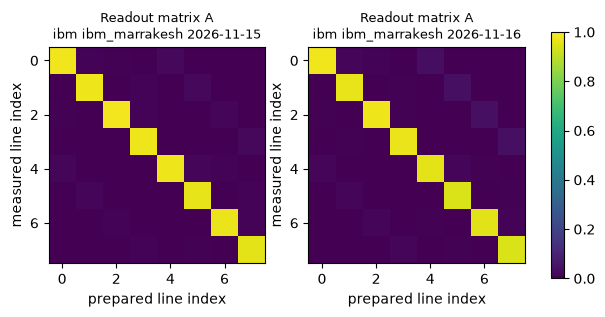

In [5]:
if saved:
    display(plots.table(
        ["job", "shots", "ε", "shots for ≤1% misses", "cutoffs", "correct readout per line index"],
        [(job.label, job.first["shots"], f"{job.measured_profile.epsilon:.3f}",
          job.measured_profile.shots_needed(0.01, job.first["budget"]) or "more than 16384", job.first["cutoffs"],
          ", ".join(f"{job.measured_profile.readout[i][i]:.3f}" for i in range(8))) for job in saved], "lrrrll"))
    plots.readout_matrices({job.label: job.measured_profile for job in saved})
    plt.show()

## 3. Every board

**Reading the bar charts:** each bar is the share of shots measured on a line
index. Green: the board's real winning lines. Gray: losing lines. Orange,
hatched and marked x: a losing line that reached its cutoff, so it was flagged
and then rejected by the classical check. The black tick on each bar is that
line's cutoff (from the noise profile measured in the job), and the dotted
line is 1/8, an even spread over all 8 lines. The line indices:

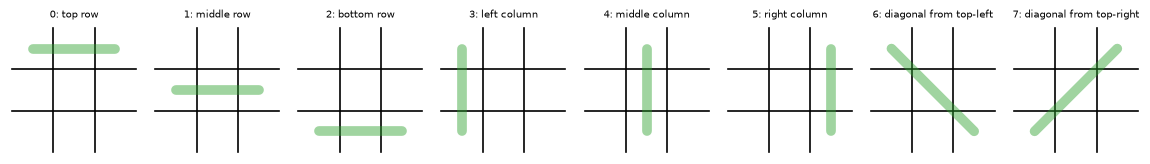

In [6]:
plots.line_key(bits=False)
plt.show()

**ibm ibm_marrakesh 2026-11-15**, 1024 shots

| # | board | confirmed | rejected | share on winning lines | verdict |
| ---: | :--- | :--- | :--- | ---: | :--- |
| 1 | no winner (X just moved, turn 5) | [] | [] | - | correct |
| 2 | X wins the top row (turn 5) | [] | [2] | 16.2% | **MISSED** |
| 3 | X wins the middle row and left column (turn 9) | [] | [0] | 29.4% | **MISSED** |

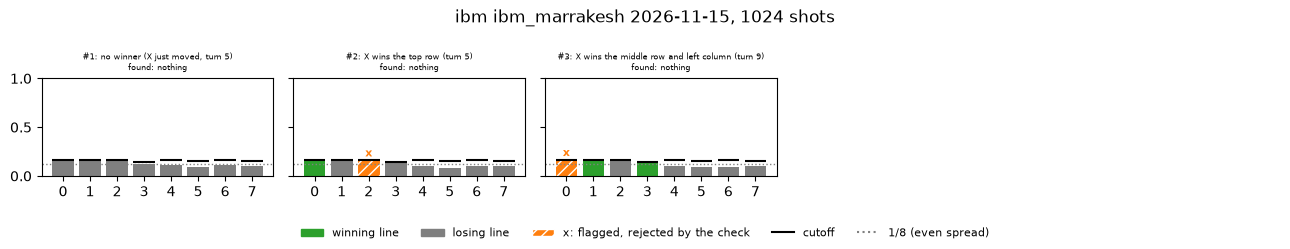

**ibm ibm_marrakesh 2026-11-16**, 2048 shots: the 20 boards that missed a line or flagged a losing one; the other 28 were correct with no false flag

| # | board | confirmed | rejected | share on winning lines | verdict |
| ---: | :--- | :--- | :--- | ---: | :--- |
| 4 | X wins the right column and diagonal from top-right (turn 9) | [] | [] | 28.6% | **MISSED** |
| 8 | X wins the bottom row and middle column (turn 9) | [2] | [] | 30.7% | **partly missed** |
| 9 | X wins the left column and diagonal from top-left (turn 9) | [3] | [] | 30.4% | **partly missed** |
| 17 | X wins the right column (turn 7) | [] | [] | 14.9% | **MISSED** |
| 18 | X wins the middle column and diagonal from top-right (turn 9) | [] | [] | 25.8% | **MISSED** |
| 23 | X wins the diagonal from top-right (turn 5) | [] | [] | 14.9% | **MISSED** |
| 24 | X wins the middle row and left column (turn 9) | [] | [] | 29.3% | **MISSED** |
| 25 | O wins the diagonal from top-right (turn 8) | [] | [] | 13.9% | **MISSED** |
| 26 | O wins the diagonal from top-left (turn 6) | [] | [] | 12.8% | **MISSED** |
| 30 | X wins the top row and right column (turn 9) | [0] | [] | 32.1% | **partly missed** |
| 33 | X wins the left column and diagonal from top-right (turn 9) | [] | [] | 26.5% | **MISSED** |
| 36 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [] | [] | 26.8% | **MISSED** |
| 38 | X wins the middle row and diagonal from top-left (turn 9) | [1] | [] | 29.5% | **partly missed** |
| 41 | X wins the top row and diagonal from top-left (turn 9) | [0] | [] | 29.6% | **partly missed** |
| 42 | X wins the bottom row and right column (turn 9) | [2] | [] | 32.5% | **partly missed** |
| 43 | X wins the top row and left column (turn 9) | [0] | [] | 32.3% | **partly missed** |
| 44 | X wins the top row and diagonal from top-right (turn 9) | [0] | [] | 31.9% | **partly missed** |
| 45 | X wins the bottom row and diagonal from top-left (turn 9) | [2] | [] | 31.0% | **partly missed** |
| 46 | X wins the right column and diagonal from top-left (turn 9) | [] | [] | 28.5% | **MISSED** |
| 47 | X wins the top row and middle column (turn 9) | [0] | [] | 30.5% | **partly missed** |

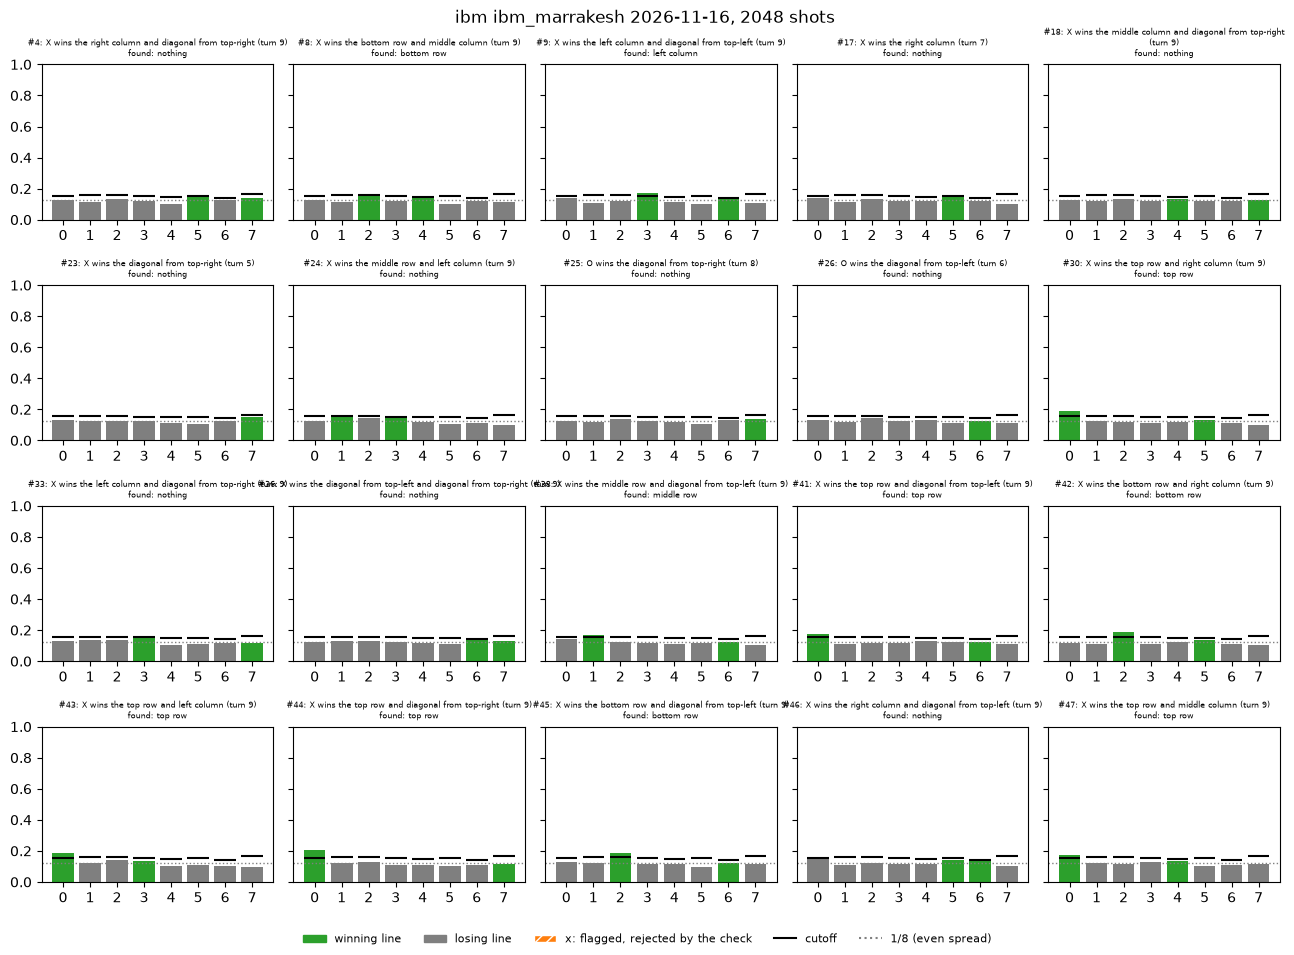

In [7]:
SHOW_ALL = 30  # larger jobs list only the boards that missed a line or flagged a losing one
MAX_PANELS = 40

for job in saved:
    numbered = list(enumerate(job.detections, start=1))
    shown = numbered if len(numbered) <= SHOW_ALL else [
        (n, r) for n, r in numbered if verdict(r) != "correct" or r["rejected"]]
    note = "" if len(shown) == len(numbered) else (
        f": the {len(shown)} boards that missed a line or flagged a losing one; the other "
        f"{len(numbered) - len(shown)} were correct with no false flag")
    display(plots.markdown(f"**{job.label}**, {job.first['shots']} shots{note}"))
    if not shown:
        continue
    display(plots.table(
        ["#", "board", "confirmed", "rejected", "share on winning lines", "verdict"],
        [(n, describe(r), r["lines"], r["rejected"],
          f"{sum(r['counts'][i] for i in r['true_lines']) / r['shots']:.1%}" if r["true_lines"] else "-",
          f"**{verdict(r)}**" if verdict(r) != "correct" else verdict(r)) for n, r in shown], "rlllrl"))
    panels = [(n, r, f"#{n}: {describe(r)}\nfound: {' and '.join(SHORT_LINE_NAMES[i] for i in r['lines']) or 'nothing'}")
              for n, r in shown[:MAX_PANELS]]
    more = f" (first {MAX_PANELS} of {len(shown)})" if len(shown) > MAX_PANELS else ""
    plots.board_bars(panels, f"{job.label}, {job.first['shots']} shots{more}")
    plt.show()

## 4. Results by kind of board

- **Win found:** at least one winning line confirmed; **all lines** counts
  double wins only when both lines were found.
- **False flag:** a losing line reached its cutoff. The classical check
  rejects it, so it costs one extra check but never produces a wrong winner.
  The budget allows about 0.2 per board; clearly more on no-win boards means
  the noise is not spreading evenly over the losing lines as the model assumes.
- **Checks per board** counts classical line checks; checking every line would
  be 8. That is not a speedup: every shot evaluates all 8 lines (Part 1,
  section 10).

In [8]:
for job in saved:
    rows = []
    for row in summarize(job.detections):
        win = row.label != "no_win"
        low, high = row.found_interval
        rows.append((row.label.replace("_", " "), row.boards, f"{row.wins_found}/{row.boards}" if win else "-",
                     f"{low:.0%}–{high:.0%}" if win else "-", f"{row.all_lines_found}/{row.boards}" if win else "-",
                     row.false_flags, f"{row.checks / row.boards:.2f}"))
    display(plots.markdown(f"**{job.label}**"))
    display(plots.table(["board", "boards", "win found", "95% interval", "all lines", "false flags", "checks per board"],
                        rows, "lrrrrrr"))
if saved:
    wrong = wrong_winners([d for job in saved for d in job.detections])
    assert not wrong, f"{len(wrong)} reported line(s) were not real wins"
    print("No reported line was ever a wrong winner.")

**ibm ibm_marrakesh 2026-11-15**

| board | boards | win found | 95% interval | all lines | false flags | checks per board |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| no win | 1 | - | - | - | 0 | 0.00 |
| single win | 1 | 0/1 | 0%–79% | 0/1 | 1 | 1.00 |
| double win | 1 | 0/1 | 0%–79% | 0/1 | 1 | 1.00 |

**ibm ibm_marrakesh 2026-11-16**

| board | boards | win found | 95% interval | all lines | false flags | checks per board |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| no win | 16 | - | - | - | 0 | 0.00 |
| single win | 16 | 12/16 | 51%–90% | 12/16 | 0 | 0.75 |
| double win | 16 | 10/16 | 39%–82% | 0/16 | 0 | 0.62 |

No reported line was ever a wrong winner.


## 5. Measured vs predicted

For each board with a winner: the share of shots on its winning line(s),
measured in the job, next to two predictions of the same simple model. One
uses the device's published calibration data, saved with the job when it was
submitted, for the same compiled circuit (left out for providers that publish
no gate errors). The other uses the noise profile measured in the job.

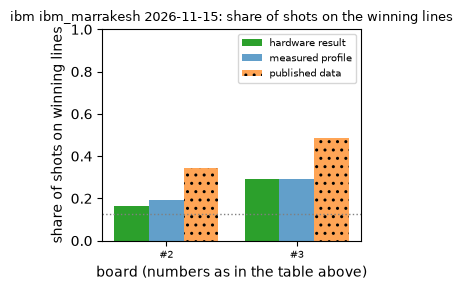

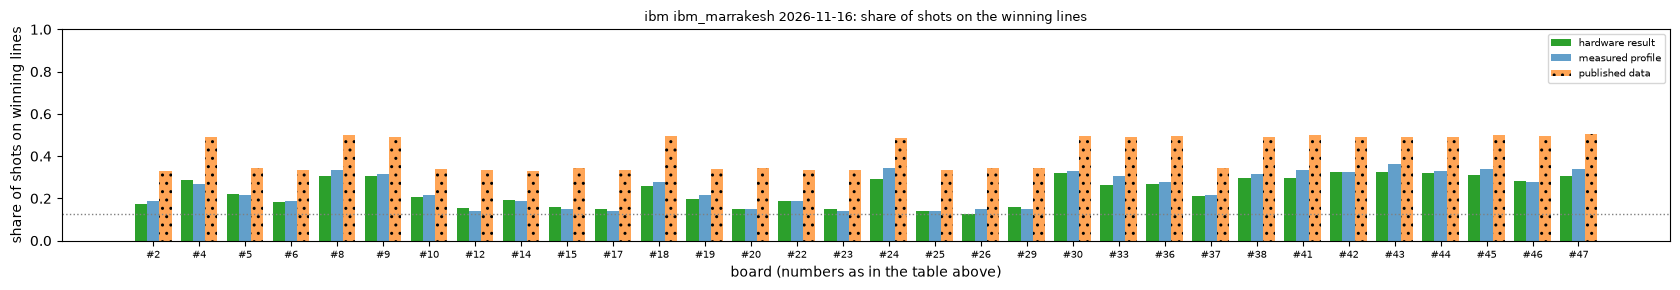

In [9]:
for job in saved:
    numbered = [(n, r) for n, r in enumerate(job.detections, start=1) if r["true_lines"]][:MAX_PANELS]
    if not numbered:
        continue
    models = {"measured profile": job.measured_profile}
    if job.published_profile is not None:
        models["published data"] = job.published_profile
    plots.measured_vs_predicted(numbered, models, f"{job.label}: share of shots on the winning lines")
    plt.show()

**What to notice:** where the published-data bar stands well above the
hardware result, the device is noisier than its published calibration says,
as Part 2 found in simulation. Both predictions use the same model; the
measured one also gives each bit of the line index its own signal factor.
Gaps on particular boards show where that model is too simple.

## 6. Conclusion

**What worked**

- **Never a wrong winner.** Every line the quantum search flags is confirmed
  on the board, so noise can cost a missed win or an extra check but never a
  false result; section 4 checks this on every saved board.
- **Measuring the noise in the same job.** Each job fits its own readout
  matrix, ε and per-bit signal from 20 calibration circuits, so the cutoffs
  follow the device on the day rather than a published snapshot, which Part 2
  showed understates the noise.
- **A circuit small enough to try.** Cutting the class circuit from 22 qubits
  to 12 (Part 1) is what leaves any signal at all.

**What did not**

- **Today's noise is close to the limit for this circuit.** Section 2 gives
  each job's measured ε and the shots it would need for at most 1% misses;
  where that is far above the shots used, wins are missed. That limit is the
  hardware's, not the detector logic's: the same rule finds every win on a
  perfect simulator.
- **The noise model is simple:** one ε plus a factor per bit. Section 5 shows
  where it misses.

**What next**

- A 282-board batch on ibm_kingston (tag `kingston-1`) is queued; once its
  results are saved this notebook includes it with no changes.
- Choose shots per device from a short calibration job (`--shots auto` in
  `scripts/collect.py`), so each device gets the shots its noise needs.
- Compare devices with a square qubit grid, where the compiled circuit needs
  fewer swaps (Part 1, section 9), and runs with and without IBM's error
  suppression options.

## Appendix: sending a job

Optional, IBM devices only so far, and it uses your plan's time. Put
`QISKIT_IBM_TOKEN=...` in the repo's `.env` (see `.env.example`), set
`SUBMIT_TO` and `RUN_HARDWARE = True` below, run the notebook once, then set it
back to False and re-run it to see the new job above. The same batch can be
sent from a terminal with
`python scripts/collect.py --backend ibm_kingston --n 30 --seed 4903 --shots auto --tag kingston-1`.

In [10]:
from qttt.backends import get_backend
from qttt.experiments import choose_shots, collect, sample_boards
from qttt.noise import CALIBRATION_CIRCUITS

RUN_HARDWARE = False  # True submits one job to SUBMIT_TO (uses your plan's time)
SUBMIT_TO = "ibm_kingston"
N_BOARDS = 30  # balanced over label, winning line, last mover and turn
SEED = 4903
SHOTS = "auto"  # a short calibration job first picks the shots for at most 1% misses, up to MAX_SHOTS
MAX_SHOTS = 4096
TAG = "kingston-1"

if RUN_HARDWARE:
    boards = sample_boards(N_BOARDS, seed=SEED)
    device = get_backend(SUBMIT_TO, seed=SEED, transpile_seeds=5)
    shots = SHOTS
    if shots == "auto":
        shots, _ = choose_shots(device, max_shots=MAX_SHOTS, store=STORE, tag=TAG)
        print(f"A calibration job on {SUBMIT_TO} chose {shots} shots per board.")
    print(f"Submitting {len(boards)} boards + {CALIBRATION_CIRCUITS} calibration circuits to {SUBMIT_TO}"
          f" ({shots} shots each)...")
    collect(boards, device, shots=shots, store=STORE, tag=TAG)
    print("Done; saved to", STORE.runs_file)

---

[← Part 2: noise](02_noise.ipynb) · [Part 1: how it works](01_how_it_works.ipynb) · [README](../README.md)